# 04.9 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/09-bias-variance/solutions.ipynb)

## Exercise 1

**C**: mean 60, bias +10, bias² 100. Deviations 0, 2, −2, 0 → variance (0 + 4 + 4 + 0)/4 = 2. MSE = 102.

**D**: mean 50, bias 0. Deviations −10, 15, −5, 0 → variance (100 + 225 + 25 + 0)/4 = 87.5. MSE = 87.5.

D has lower total error this time, because its variance is smaller than C's bias². Neither "low bias" nor "low variance" wins automatically; the sum decides.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

truth = 50
for name, p in [("C", np.array([60, 62, 58, 60])), ("D", np.array([40, 65, 45, 50]))]:
    b = p.mean() - truth; v = p.var()
    print(f"{name}: bias {b:+.0f}, bias² {b*b:.0f}, variance {v:.1f}, MSE {((p - truth)**2).mean():.1f}")

C: bias +10, bias² 100, variance 2.0, MSE 102.0
D: bias +0, bias² 0, variance 87.5, MSE 87.5


## Exercise 2

In [2]:
rng = np.random.default_rng(0)
def true_f(x):
    """The real (unknown) relationship: spend rises with visits, then levels off."""
    return 200 * (1 - np.exp(-x / 4))
x_grid = np.linspace(1.5, 13, 60)          # where we compare models (inside the data range)

def one_sample(n=30, noise=20):
    x = rng.uniform(0.5, 14, n)
    return x, true_f(x) + rng.normal(0, noise, n)

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
for noise in [20, 60]:
    for d in [1, 3, 9]:
        P = []
        for _ in range(100):
            x, y = one_sample(noise=noise)
            m = make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression())
            P.append(m.fit(x.reshape(-1, 1), y).predict(x_grid.reshape(-1, 1)))
        P = np.array(P)
        b2, v = ((P.mean(0) - true_f(x_grid)) ** 2).mean(), P.var(0).mean()
        print(f"noise {noise}, degree {d}: bias² {b2:8.1f}  variance {v:9.1f}  sum {b2 + v:9.1f}")

noise 20, degree 1: bias²    179.6  variance      52.2  sum     231.8
noise 20, degree 3: bias²      0.5  variance      50.5  sum      51.0
noise 20, degree 9: bias²      7.2  variance    2924.8  sum    2931.9


noise 60, degree 1: bias²    181.0  variance     207.0  sum     388.0
noise 60, degree 3: bias²      6.9  variance     415.8  sum     422.7
noise 60, degree 9: bias²    637.4  variance   55044.7  sum   55682.1


More noise inflates every model's variance, and the flexible degree-9 model most of all (from about 2,900 to about 55,000), because it chases the noise. Bias barely changes for degrees 1 and 3. With noise 60 the **straight line now has the lowest total** (about 388 against about 423 for degree 3): the noisier the data, the more a simpler model is worth.

## Exercise 3

In [3]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")                       # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])
features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%
train 2,487 / test 830


In [4]:
from sklearn.model_selection import validation_curve, StratifiedKFold, learning_curve
from sklearn.tree import DecisionTreeClassifier
skf = StratifiedKFold(5, shuffle=True, random_state=42)
leaves = [1, 2, 5, 10, 25, 50, 100, 200, 400]
tr, va = validation_curve(DecisionTreeClassifier(random_state=42), X_train, y_train,
                          param_name="min_samples_leaf", param_range=leaves, cv=skf)
for l, a, b in zip(leaves, tr.mean(1), va.mean(1)):
    print(f"min_samples_leaf {l:>3}: train {a:.3f}  CV {b:.3f}")

min_samples_leaf   1: train 1.000  CV 0.601
min_samples_leaf   2: train 0.930  CV 0.597
min_samples_leaf   5: train 0.839  CV 0.613
min_samples_leaf  10: train 0.780  CV 0.630
min_samples_leaf  25: train 0.725  CV 0.654
min_samples_leaf  50: train 0.703  CV 0.655
min_samples_leaf 100: train 0.688  CV 0.667
min_samples_leaf 200: train 0.683  CV 0.669
min_samples_leaf 400: train 0.670  CV 0.656


Small leaves (1, 2) overfit: a leaf can hold a single customer, so training accuracy is near 100% and CV is poor. Very large leaves underfit. Note the direction is the opposite of `max_depth`: here *larger* numbers mean a *simpler* model.

## Exercise 4

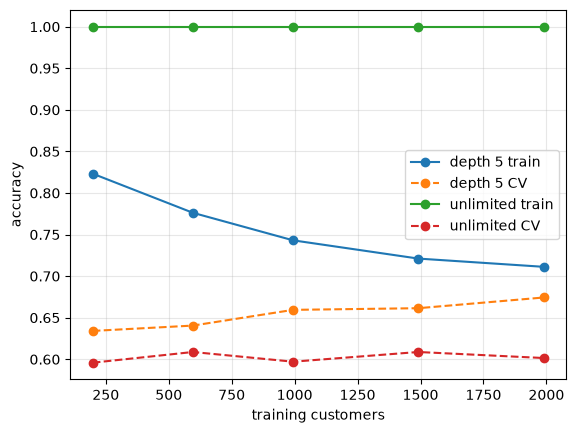

In [5]:
for name, m in [("depth 5", DecisionTreeClassifier(max_depth=5, random_state=42)),
                ("unlimited", DecisionTreeClassifier(random_state=42))]:
    sizes, tr_s, va_s = learning_curve(m, X_train, y_train, cv=skf, train_sizes=[.1, .3, .5, .75, 1.0])
    plt.plot(sizes, tr_s.mean(1), "o-", label=f"{name} train")
    plt.plot(sizes, va_s.mean(1), "o--", label=f"{name} CV")
plt.xlabel("training customers"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()

The depth-5 tree's gap is a few points; the unlimited tree's is about 40 points. Limiting depth traded a little bias for a large cut in variance.